## Mohammed Nasser Almarhoon | 2240005893 


# LAB 7(B) 


## Cell 1 — Import Libraries

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image

plt.rc('text', usetex=False)
np.random.seed(42)  # Makes the noise examples reproducible

## Cell 2 — Load the Image in Grayscale

Image loaded successfully.
Image dimensions: (506, 508)


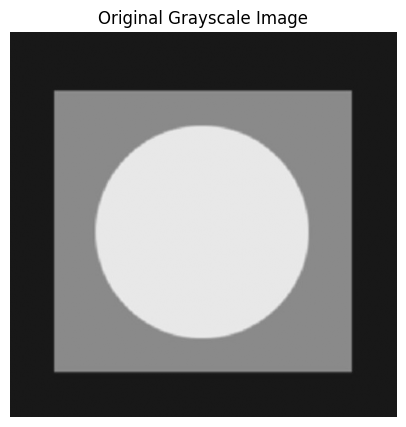

In [2]:
image_path = 'noise.jpg'
img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError(
        f"Could not load '{image_path}'. Place the image in the notebook folder "
        "or update image_path to the correct file path."
    )

print("Image loaded successfully.")
print("Image dimensions:", img.shape)

plt.figure(figsize=(6, 5))
plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.title('Original Grayscale Image')
plt.axis('off')
plt.show()

## Cell 3 — Define the Noise-Adding Function
The function below supports four noise types. Pixel values are clipped to the valid grayscale range of 0–255.

In [3]:
def add_noise(image, noise_type):
    image_float = image.astype(np.float64)
    rows, cols = image.shape

    if noise_type == "gaussian":
        # Gaussian noise with zero mean and standard deviation of 0.1 * 255.
        mean = 0
        sigma = 0.1 * 255
        noise = np.random.normal(mean, sigma, (rows, cols))
        noisy = image_float + noise

    elif noise_type == "salt_pepper":
        # Randomly replace 4% of pixels: half white (salt), half black (pepper).
        noisy = image.copy()
        amount = 0.04
        num_pixels = int(amount * image.size)
        num_salt = num_pixels // 2
        num_pepper = num_pixels - num_salt

        all_indices = np.random.choice(image.size, num_pixels, replace=False)
        salt_indices = all_indices[:num_salt]
        pepper_indices = all_indices[num_salt:]

        noisy.flat[salt_indices] = 255
        noisy.flat[pepper_indices] = 0
        return noisy

    elif noise_type == "exponential":
        # Add non-negative exponential noise.
        noise = np.random.exponential(scale=10.0, size=(rows, cols))
        noisy = image_float + noise

    elif noise_type == "uniform":
        # Add uniformly distributed noise in the range [-20, 20].
        noise = np.random.uniform(-20, 20, (rows, cols))
        noisy = image_float + noise

    else:
        raise ValueError(
            "Unsupported noise_type. Choose 'gaussian', 'salt_pepper', "
            "'exponential', or 'uniform'."
        )

    return np.clip(noisy, 0, 255).astype(np.uint8)

## Cell 4 — Generate and Display All Four Noisy Images

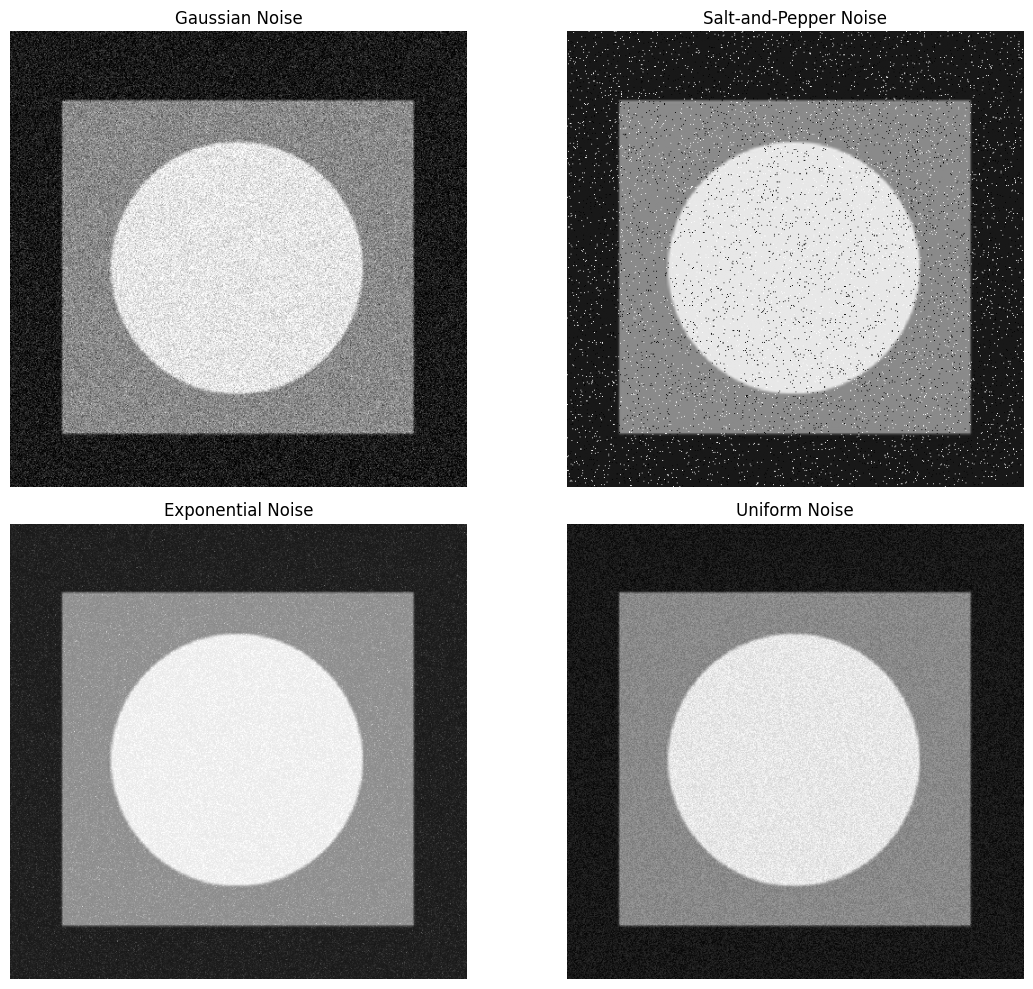

In [4]:
noise_gauss = add_noise(img, "gaussian")
noise_sp = add_noise(img, "salt_pepper")
noise_expo = add_noise(img, "exponential")
noise_uni = add_noise(img, "uniform")

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
images = [
    (noise_gauss, 'Gaussian Noise'),
    (noise_sp, 'Salt-and-Pepper Noise'),
    (noise_expo, 'Exponential Noise'),
    (noise_uni, 'Uniform Noise')
]

for ax, (image, title) in zip(axes.flat, images):
    ax.imshow(image, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')

plt.tight_layout()
plt.show()

## Cell 5 — Arithmetic Mean Filter (Built-in OpenCV Method)
The arithmetic mean filter replaces each pixel with the average of values in its local neighborhood.

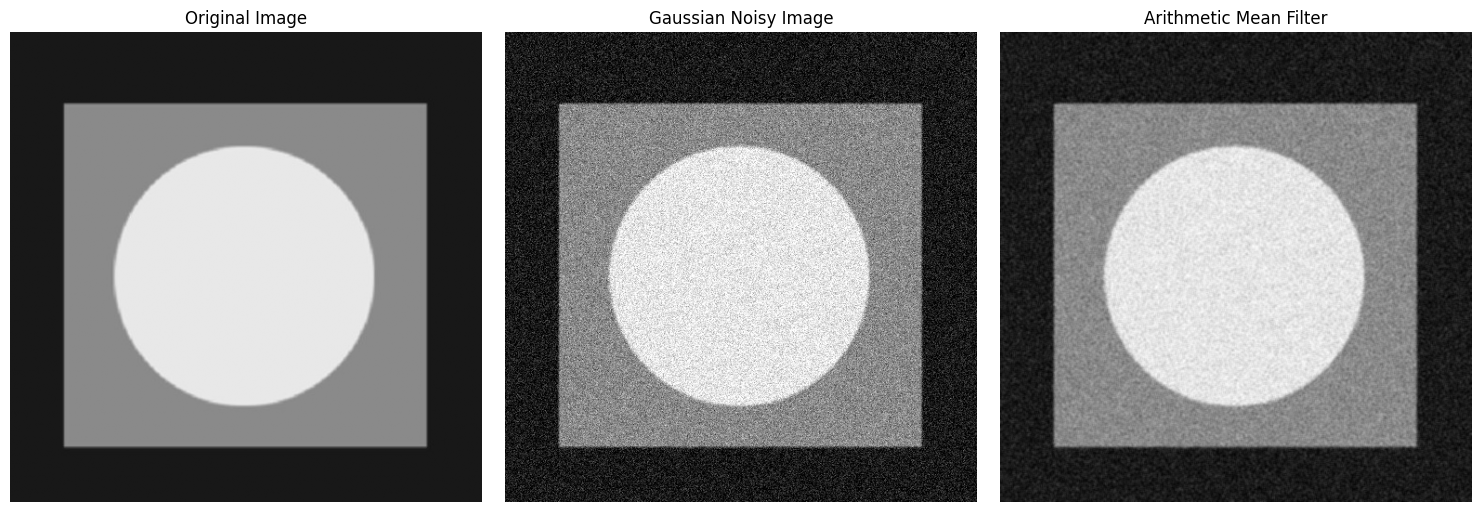

In [5]:
kernel_size = 3
arithmetic_mean_builtin = cv2.blur(noise_gauss, (kernel_size, kernel_size))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Original Image')
axes[1].imshow(noise_gauss, cmap='gray', vmin=0, vmax=255)
axes[1].set_title('Gaussian Noisy Image')
axes[2].imshow(arithmetic_mean_builtin, cmap='gray', vmin=0, vmax=255)
axes[2].set_title('Arithmetic Mean Filter')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## Cell 6 — Arithmetic Mean Filter (Manual Kernel Method)
A mean kernel contains equal weights whose sum is 1. This cell applies the kernel to the same noisy image for a fair comparison.

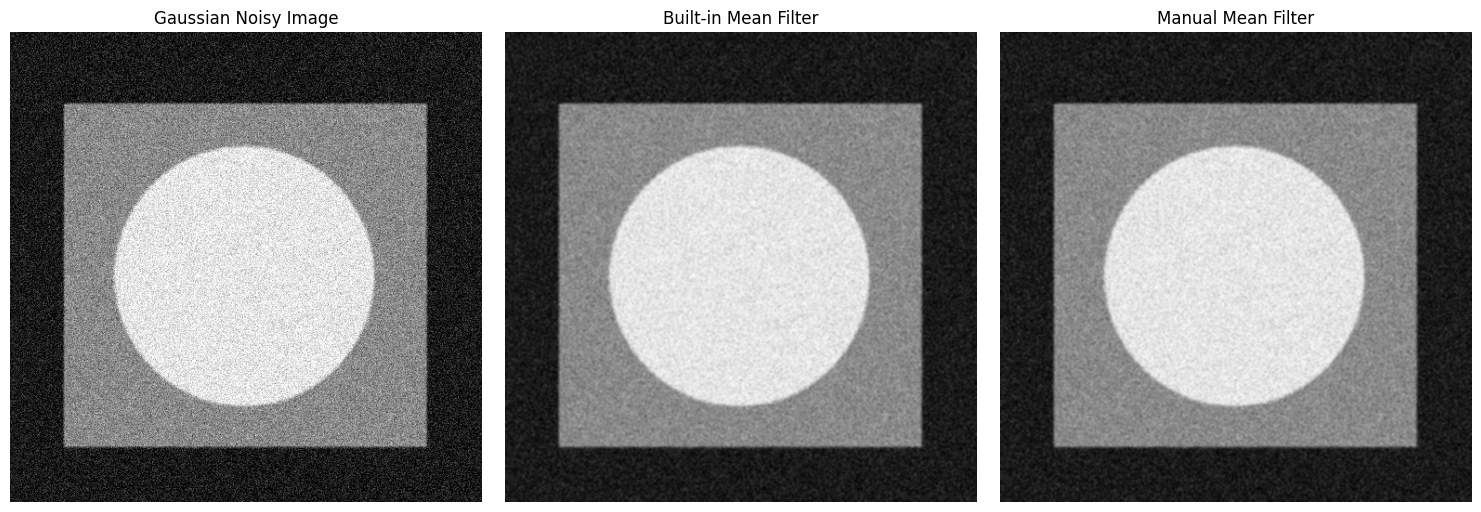

In [6]:
kernel_size = 3
mean_kernel = np.ones((kernel_size, kernel_size), dtype=np.float32) / (kernel_size ** 2)
arithmetic_mean_manual = cv2.filter2D(noise_gauss, ddepth=-1, kernel=mean_kernel)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(noise_gauss, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Gaussian Noisy Image')
axes[1].imshow(arithmetic_mean_builtin, cmap='gray', vmin=0, vmax=255)
axes[1].set_title('Built-in Mean Filter')
axes[2].imshow(arithmetic_mean_manual, cmap='gray', vmin=0, vmax=255)
axes[2].set_title('Manual Mean Filter')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## Cell 7 — Geometric Mean Filter
The geometric mean is computed by averaging logarithms in each neighborhood and then applying the exponential function. A small epsilon prevents `log(0)`.

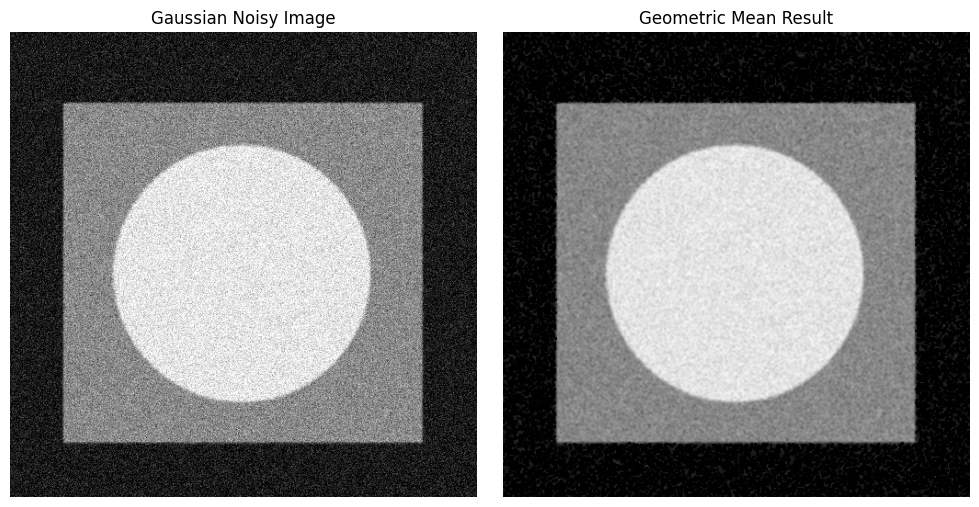

In [7]:
def geometric_mean_filter(image, kernel_size=3):
    if kernel_size < 1 or kernel_size % 2 == 0:
        raise ValueError("kernel_size must be a positive odd integer.")

    image_float = image.astype(np.float64) + 1e-6
    log_image = np.log(image_float)
    kernel = np.ones((kernel_size, kernel_size), dtype=np.float64) / (kernel_size ** 2)
    mean_log = cv2.filter2D(log_image, ddepth=-1, kernel=kernel)
    geometric_mean = np.exp(mean_log)

    return np.clip(geometric_mean, 0, 255).astype(np.uint8)


geometric_result = geometric_mean_filter(noise_gauss, kernel_size=3)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(noise_gauss, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Gaussian Noisy Image')
axes[1].imshow(geometric_result, cmap='gray', vmin=0, vmax=255)
axes[1].set_title('Geometric Mean Result')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## Cell 8 — Harmonic Mean Filter
The harmonic mean filter uses the reciprocal values in each neighborhood. It is often useful for reducing salt (bright) noise, but it is not a universal solution for every noise type.

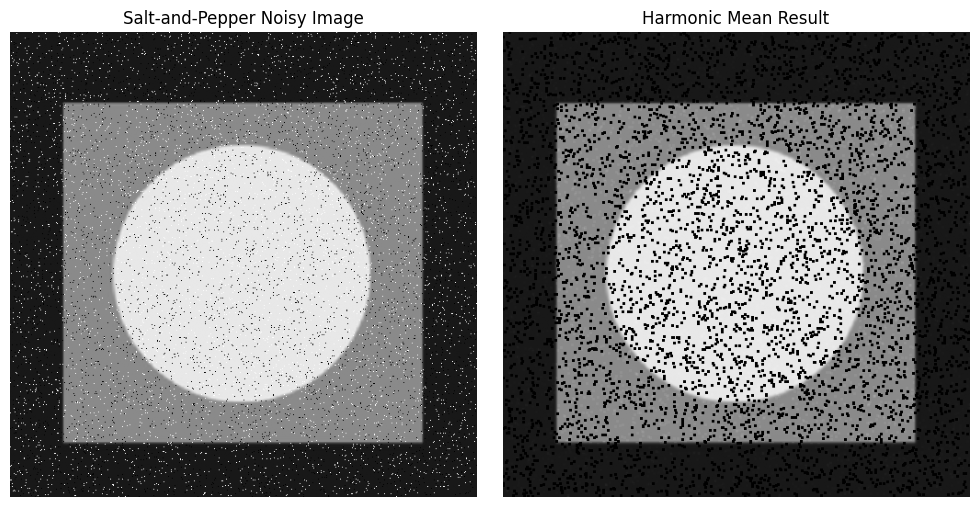

In [8]:
def harmonic_mean_filter(image, kernel_size=3):
    if kernel_size < 1 or kernel_size % 2 == 0:
        raise ValueError("kernel_size must be a positive odd integer.")

    image_float = image.astype(np.float64) + 1e-6
    reciprocal_image = 1.0 / image_float
    kernel = np.ones((kernel_size, kernel_size), dtype=np.float64)
    sum_reciprocal = cv2.filter2D(reciprocal_image, ddepth=-1, kernel=kernel)

    n = kernel_size ** 2
    harmonic_mean = n / np.maximum(sum_reciprocal, 1e-12)
    return np.clip(harmonic_mean, 0, 255).astype(np.uint8)


harmonic_result = harmonic_mean_filter(noise_sp, kernel_size=3)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(noise_sp, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Salt-and-Pepper Noisy Image')
axes[1].imshow(harmonic_result, cmap='gray', vmin=0, vmax=255)
axes[1].set_title('Harmonic Mean Result')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## Cell 9 — Contra-Harmonic Mean Filter
The contra-harmonic mean filter depends on parameter `Q`:
- `Q > 0` is used to reduce pepper noise (black pixels).
- `Q < 0` is used to reduce salt noise (white pixels).

Use the Salt-and-Pepper image here so that the effect of `Q` can be examined.

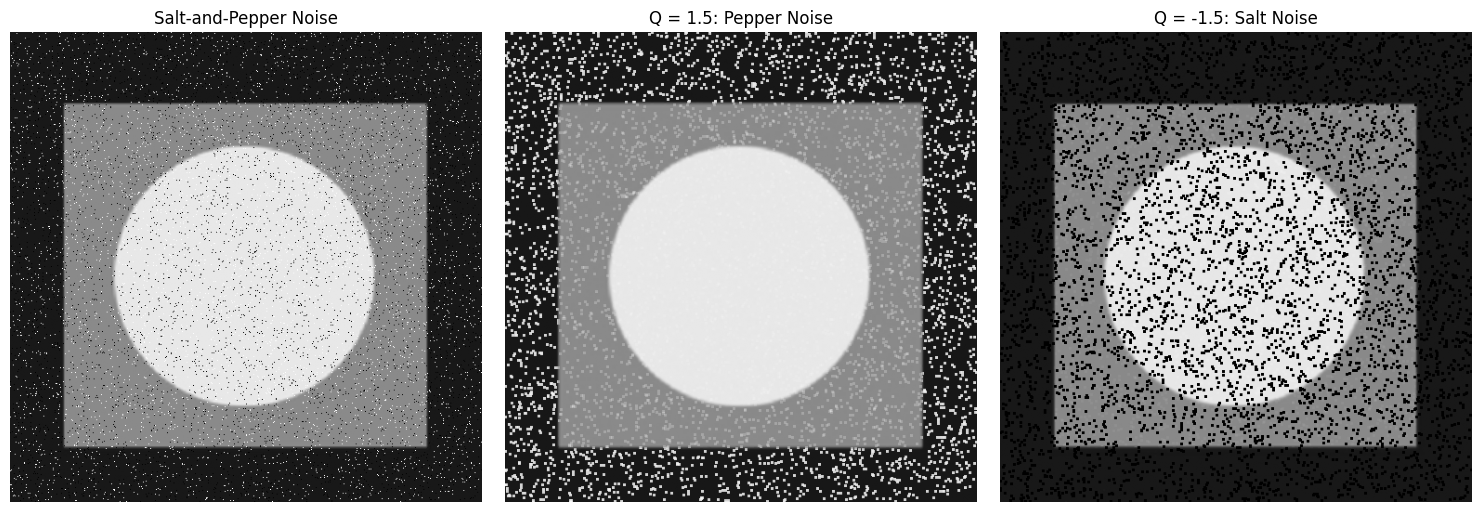

In [9]:
def contra_harmonic_mean_filter(image, kernel_size=3, Q=1.5):
    if kernel_size < 1 or kernel_size % 2 == 0:
        raise ValueError("kernel_size must be a positive odd integer.")

    # Avoid zero raised to a negative power when Q is negative.
    image_float = np.maximum(image.astype(np.float64), 1e-6)
    kernel = np.ones((kernel_size, kernel_size), dtype=np.float64)

    numerator = cv2.filter2D(np.power(image_float, Q + 1), ddepth=-1, kernel=kernel)
    denominator = cv2.filter2D(np.power(image_float, Q), ddepth=-1, kernel=kernel)
    result = numerator / np.maximum(denominator, 1e-12)

    return np.clip(result, 0, 255).astype(np.uint8)


pepper_removed = contra_harmonic_mean_filter(noise_sp, kernel_size=3, Q=1.5)
salt_removed = contra_harmonic_mean_filter(noise_sp, kernel_size=3, Q=-1.5)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(noise_sp, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Salt-and-Pepper Noise')
axes[1].imshow(pepper_removed, cmap='gray', vmin=0, vmax=255)
axes[1].set_title('Q = 1.5: Pepper Noise')
axes[2].imshow(salt_removed, cmap='gray', vmin=0, vmax=255)
axes[2].set_title('Q = -1.5: Salt Noise')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## Cell 10 — Median Filter
The median filter replaces each pixel with the median value in its neighborhood. It is especially effective for Salt-and-Pepper noise. The kernel size must be an odd integer.

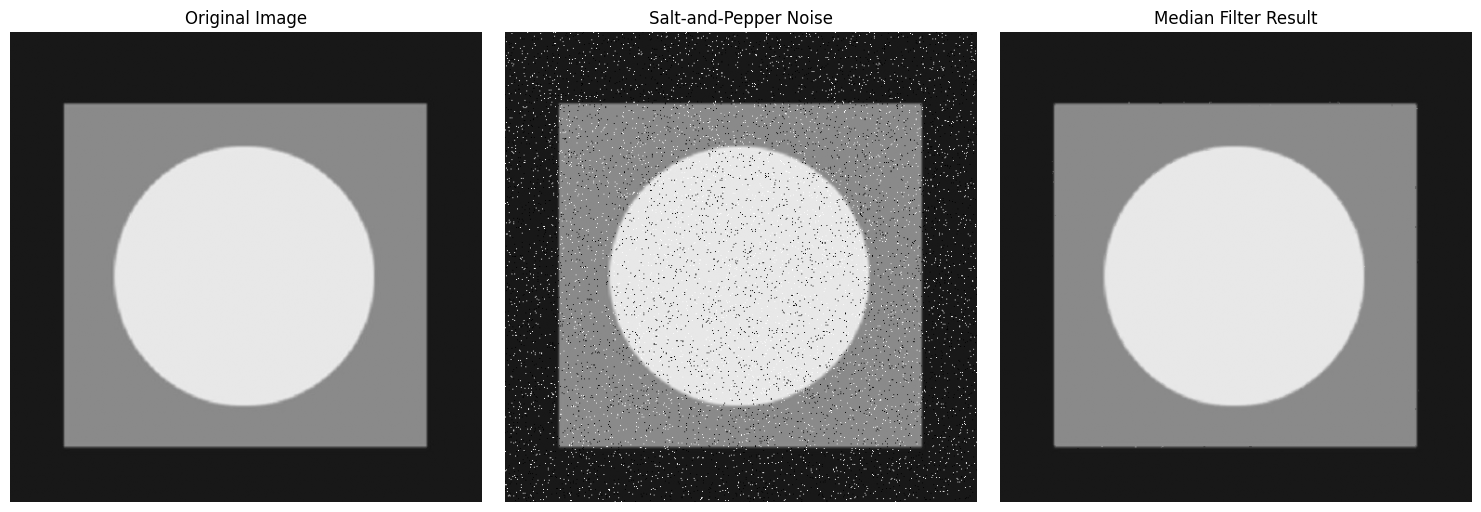

In [10]:
median_result = cv2.medianBlur(noise_sp, 3)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Original Image')
axes[1].imshow(noise_sp, cmap='gray', vmin=0, vmax=255)
axes[1].set_title('Salt-and-Pepper Noise')
axes[2].imshow(median_result, cmap='gray', vmin=0, vmax=255)
axes[2].set_title('Median Filter Result')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## Cell 11 — Max and Min Filters
The max filter selects the brightest value in each neighborhood and can reduce isolated black pixels. The min filter selects the darkest value and can reduce isolated white pixels. These filters can also expand bright or dark regions, so inspect the results carefully.

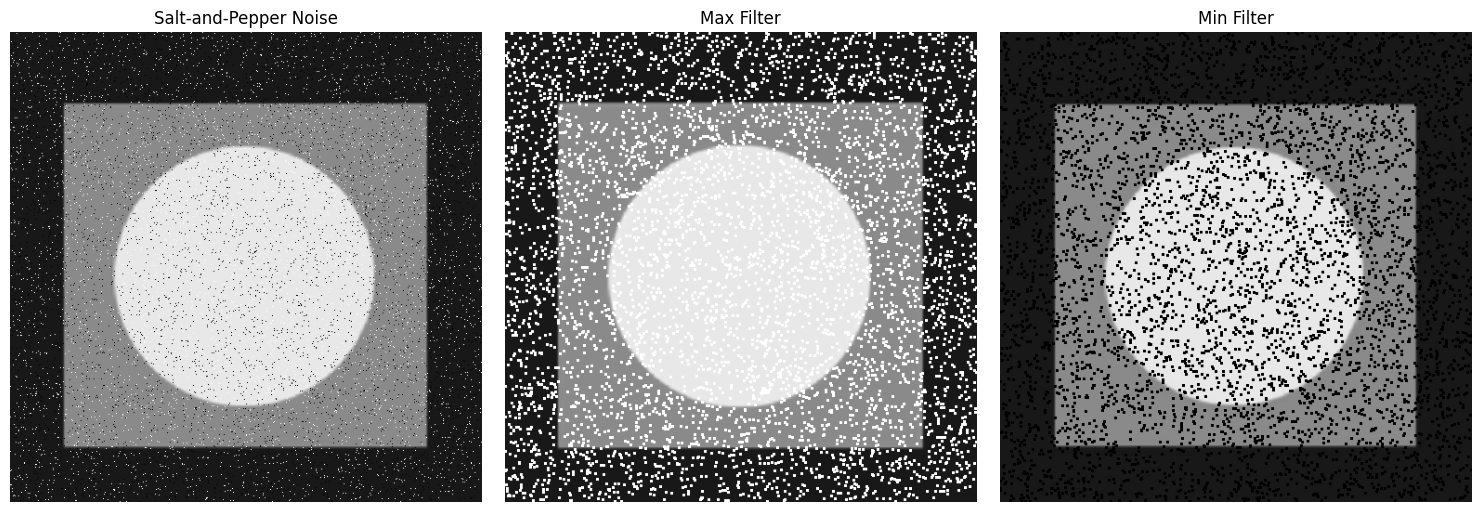

In [11]:
kernel = np.ones((3, 3), dtype=np.uint8)

max_filter_result = cv2.dilate(noise_sp, kernel)
min_filter_result = cv2.erode(noise_sp, kernel)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(noise_sp, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Salt-and-Pepper Noise')
axes[1].imshow(max_filter_result, cmap='gray', vmin=0, vmax=255)
axes[1].set_title('Max Filter')
axes[2].imshow(min_filter_result, cmap='gray', vmin=0, vmax=255)
axes[2].set_title('Min Filter')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## Cell 12 — Midpoint Filter
The midpoint filter averages the maximum and minimum values in each local neighborhood. It is commonly tested with Gaussian or Uniform noise.

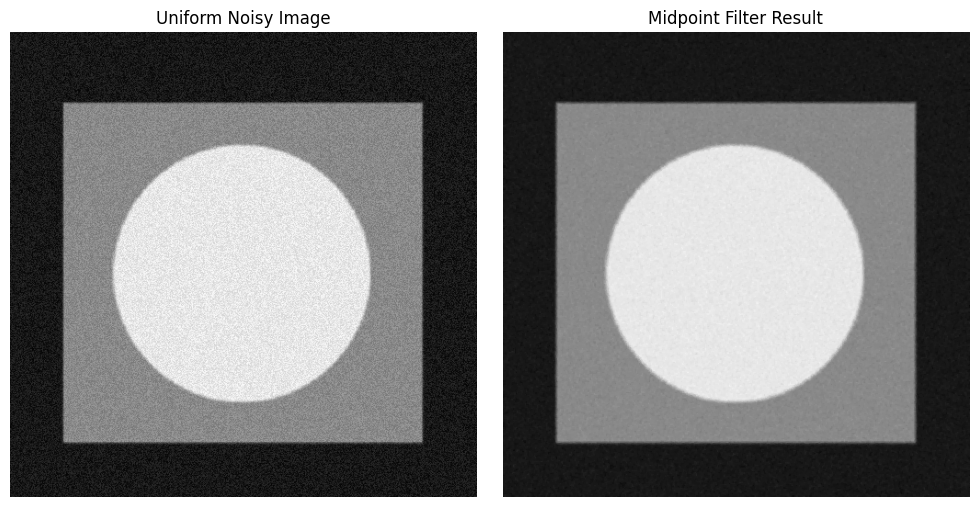

In [12]:
def midpoint_filter(image, kernel_size=3):
    if kernel_size < 1 or kernel_size % 2 == 0:
        raise ValueError("kernel_size must be a positive odd integer.")

    kernel = np.ones((kernel_size, kernel_size), dtype=np.uint8)
    local_max = cv2.dilate(image, kernel).astype(np.float64)
    local_min = cv2.erode(image, kernel).astype(np.float64)
    midpoint = (local_max + local_min) / 2.0

    return np.clip(midpoint, 0, 255).astype(np.uint8)


midpoint_result = midpoint_filter(noise_uni, kernel_size=3)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(noise_uni, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Uniform Noisy Image')
axes[1].imshow(midpoint_result, cmap='gray', vmin=0, vmax=255)
axes[1].set_title('Midpoint Filter Result')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## Cell 13 — Quantitative Evaluation (MSE and PSNR)
Mean Squared Error (MSE) and Peak Signal-to-Noise Ratio (PSNR) provide a numerical comparison with the original image. Higher PSNR and lower MSE generally indicate closer similarity to the original. These metrics are most meaningful when comparing images of the same scene.

In [13]:
def calculate_mse(reference, test):
    reference_float = reference.astype(np.float64)
    test_float = test.astype(np.float64)
    return np.mean((reference_float - test_float) ** 2)


def calculate_psnr(reference, test):
    mse = calculate_mse(reference, test)
    if mse == 0:
        return float('inf')
    max_pixel = 255.0
    return 10 * np.log10((max_pixel ** 2) / mse)


results = {
    'Gaussian noisy': noise_gauss,
    'Mean filter': arithmetic_mean_builtin,
    'Geometric mean filter': geometric_result,
    'Harmonic mean filter': harmonic_result,
    'Contra-harmonic (Q=1.5)': pepper_removed,
    'Contra-harmonic (Q=-1.5)': salt_removed,
    'Median filter': median_result,
    'Max filter': max_filter_result,
    'Min filter': min_filter_result,
    'Midpoint filter': midpoint_result
}

print(f"{'Image / Result':<30} {'MSE':>12} {'PSNR (dB)':>12}")
print("-" * 56)

for name, result_image in results.items():
    # Compare each result against the original image of the same dimensions.
    mse_value = calculate_mse(img, result_image)
    psnr_value = calculate_psnr(img, result_image)
    print(f"{name:<30} {mse_value:>12.2f} {psnr_value:>12.2f}")

Image / Result                          MSE    PSNR (dB)
--------------------------------------------------------
Gaussian noisy                       534.44        20.85
Mean filter                           64.80        30.01
Geometric mean filter                248.56        24.18
Harmonic mean filter                3176.59        13.11
Contra-harmonic (Q=1.5)             2632.22        13.93
Contra-harmonic (Q=-1.5)            3176.92        13.11
Median filter                          0.56        50.63
Max filter                          4636.79        11.47
Min filter                          3199.48        13.08
Midpoint filter                       12.53        37.15


## Cell 14 — Summary

- **Gaussian noise:** Random noise modeled with a Gaussian distribution.
- **Salt-and-Pepper noise:** Random black and white pixels.
- **Exponential noise:** Non-negative noise added to pixel values.
- **Uniform noise:** Random values drawn uniformly from a specified interval.
- **Arithmetic mean filter:** Averages neighborhood values and smooths the image.
- **Geometric mean filter:** Uses the geometric average of neighborhood values.
- **Harmonic mean filter:** Uses reciprocal values and can help reduce salt noise.
- **Contra-harmonic mean filter:** The sign of `Q` determines which impulse-noise type is targeted.
- **Median filter:** Replaces each pixel with the neighborhood median and is useful for Salt-and-Pepper noise.
- **Max filter:** Selects the neighborhood maximum.
- **Min filter:** Selects the neighborhood minimum.
- **Midpoint filter:** Averages the neighborhood maximum and minimum.
